# Entraînement du GAN — DCGAN, loss BCE non-saturante

Architecture **DCGAN** (64×64) avec une loss **BCE non-saturante**. Dataset
et transformations dans `gan_dataset.py` ; architecture dans `gan_models.py`.
`EPOCHS = 300` par défaut sur le sous-échantillon stratifié
(`data/subset_sample.csv`), avec reprise automatique par checkpoints.

**Plan.**
1. Données (sous-échantillon stratifié)
2. Modèles (G, D) et initialisation
2bis. Reprise depuis un checkpoint existant
3. Loss et optimiseurs
4. Boucle d'entraînement (checkpoints périodiques)
5. Courbes de loss et progression visuelle
6. Comparaison finale réel vs généré
7. Confirmation de sauvegarde


## 0. Compatibilité Colab

**Résultat.** Modules (`scrape_images.py`, `gan_dataset.py`, `gan_models.py`)
réécrits automatiquement au démarrage, sur Drive si Colab — corrige le
`ModuleNotFoundError` observé en pratique.


In [1]:
import os
from pathlib import Path

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/GAN")
else:
    BASE = Path.cwd()

BASE.mkdir(parents=True, exist_ok=True)
os.chdir(BASE)
print("Dossier de travail :", Path.cwd())
print("images/ présent :", (BASE / "images").exists())


Dossier de travail : C:\Users\bamiy\Documents\GAN
images/ présent : True


In [ ]:
%%writefile scrape_images.py
"""
Télécharge les images des peintures depuis les pages wga.hu référencées dans
data/paintings_only.csv (colonne URL).

Mapping observé sur le site : une page HTML
    https://www.wga.hu/html/{a}/{artiste}/{oeuvre}.html
a toujours son image pleine résolution à
    https://www.wga.hu/art/{a}/{artiste}/{oeuvre}.jpg

"""


import argparse
import csv
import time
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import requests

USER_AGENT = "Mozilla/5.0 (compatible; EDA-research-script/1.0; personal/educational GAN dataset project)"


def html_url_to_image_url(html_url: str) -> str:
    return html_url.replace("/html/", "/art/").replace(".html", ".jpg")


def target_path(html_url: str, out_dir: Path) -> Path:
    # mirrors the /a/artiste/oeuvre.jpg structure sous out_dir/, pour garantir
    # des noms de fichiers uniques et pouvoir retrouver la ligne CSV d'origine.
    tail = html_url.split("/html/", 1)[1]  # ex: a/aachen/adonis.html
    return out_dir / Path(tail).with_suffix(".jpg")


def download_one(session, html_url, out_dir, timeout, min_delay, max_retries) -> tuple:
    img_url = html_url_to_image_url(html_url)
    dest = target_path(html_url, out_dir)

    if dest.exists() and dest.stat().st_size > 0:
        return html_url, "skip (déjà présent)"

    dest.parent.mkdir(parents=True, exist_ok=True)

    last_err = ""
    for attempt in range(1, max_retries + 1):
        try:
            time.sleep(min_delay + random.uniform(0, 0.2))
            resp = session.get(img_url, timeout=timeout)
            if resp.status_code == 200 and resp.content:
                dest.write_bytes(resp.content)
                return html_url, "ok"
            last_err = f"http {resp.status_code}"
        except requests.RequestException as e:
            last_err = str(e)
        time.sleep(1.5 * attempt)  # backoff
    return html_url, f"échec ({last_err})"


def scrape(csv_path, out_dir, limit=None, workers=4, min_delay=0.4, timeout=20, max_retries=3):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    failed_log = out_dir / "_failed.csv"

    with open(csv_path, encoding="utf-8") as f:
        urls = [row["URL"] for row in csv.DictReader(f)]
    if limit:
        urls = urls[:limit]

    print(f"{len(urls):,} images à traiter (concurrence = {workers})")

    session = requests.Session()
    session.headers.update({"User-Agent": USER_AGENT})

    ok = skip = fail = 0
    failures = []
    t0 = time.time()

    with ThreadPoolExecutor(max_workers=workers) as ex:
        futures = {
            ex.submit(download_one, session, u, out_dir, timeout, min_delay, max_retries): u
            for u in urls
        }
        for i, fut in enumerate(as_completed(futures), 1):
            url, status = fut.result()
            if status == "ok":
                ok += 1
            elif status.startswith("skip"):
                skip += 1
            else:
                fail += 1
                failures.append((url, status))

            if i % 200 == 0 or i == len(urls):
                elapsed = time.time() - t0
                rate = i / elapsed if elapsed > 0 else 0
                print(f"  {i:,}/{len(urls):,}  ok={ok} skip={skip} fail={fail}  "
                      f"({rate:.1f} img/s, {elapsed/60:.1f} min écoulées)")

    if failures:
        with open(failed_log, "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["URL", "erreur"])
            w.writerows(failures)
        print(f"\n{len(failures)} échecs loggés dans {failed_log}")

    print(f"\nTerminé en {(time.time()-t0)/60:.1f} min — ok={ok} skip={skip} fail={fail}")
    return ok, skip, fail


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", default="data/paintings_only.csv", help="CSV source (colonne URL)")
    ap.add_argument("--out", default="images", help="dossier de destination des images")
    ap.add_argument("--limit", type=int, default=None, help="ne traiter que les N premières lignes (test)")
    ap.add_argument("--workers", type=int, default=4, help="requêtes en parallèle")
    ap.add_argument("--min-delay", type=float, default=0.4, help="délai mini entre deux requêtes par worker (s)")
    ap.add_argument("--timeout", type=float, default=20, help="timeout réseau par requête (s)")
    ap.add_argument("--max-retries", type=int, default=3)
    args = ap.parse_args()

    scrape(args.csv, args.out, args.limit, args.workers, args.min_delay, args.timeout, args.max_retries)


if __name__ == "__main__":
    main()


In [ ]:
%%writefile gan_dataset.py
"""
Dataset partagé entre les notebooks de prétraitement et d'entraînement du GAN.
Reprend la logique validée dans preprocessing_images.ipynb (validation,
filtrage des formats extrêmes, center-crop + resize, normalisation [-1, 1]).
"""
import csv
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

from scrape_images import target_path


def center_crop_resize(img: Image.Image, size: int) -> Image.Image:
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return img.crop((left, top, left + side, top + side)).resize((size, size), Image.BICUBIC)


def is_valid_image(path: Path) -> bool:
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            im.load()
        return True
    except Exception:
        return False


def filter_by_format(paths, min_ratio=0.4, max_ratio=2.5, min_side=64):
    """Ne garde que les fichiers lisibles et dans la plage de format retenue par l'EDA."""
    kept = []
    for p in paths:
        if not is_valid_image(p):
            continue
        with Image.open(p) as im:
            w, h = im.size
        if min_ratio <= (w / h) <= max_ratio and min(w, h) >= min_side:
            kept.append(p)
    return kept


def list_valid_images(images_dir, min_ratio=0.4, max_ratio=2.5, min_side=64):
    """Tous les .jpg valides sous images_dir (scan brut, sans filtrage par sous-échantillon)."""
    return filter_by_format(sorted(Path(images_dir).rglob("*.jpg")), min_ratio, max_ratio, min_side)


def subset_image_paths(csv_path, images_dir, min_ratio=0.4, max_ratio=2.5, min_side=64):
    """
    Chemins locaux des images du sous-échantillon équilibré (data/subset_sample.csv),
    limités à celles réellement déjà téléchargées sur disque. À préférer à
    list_valid_images() pour l'entraînement : évite de mélanger le sous-échantillon
    stratifié avec d'éventuels fichiers de test téléchargés en dehors de ce tirage.
    """
    images_dir = Path(images_dir)
    with open(csv_path, encoding="utf-8") as f:
        urls = [row["URL"] for row in csv.DictReader(f)]

    candidates = [target_path(u, images_dir) for u in urls]
    on_disk = [p for p in candidates if p.exists()]
    return filter_by_format(on_disk, min_ratio, max_ratio, min_side)


class PaintingsDataset(Dataset):
    def __init__(self, paths, size=64):
        self.paths = list(paths)
        self.transform = transforms.Compose([
            transforms.Lambda(lambda im: im.convert("RGB")),
            transforms.Lambda(lambda im: center_crop_resize(im, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            with Image.open(self.paths[idx]) as im:
                return self.transform(im)
        except Exception:
            return self.__getitem__((idx + 1) % len(self))


In [ ]:
%%writefile gan_models.py
"""
Architecture DCGAN (Radford et al., 2015) — générateur/discriminateur
convolutionnels, sortie 64x64. Choisie pour sa sobriété : entraînable en
CPU-only sur un petit corpus, bien documentée, point de départ standard avant
d'envisager hinge loss / WGAN-GP si le mode collapse apparaît.
"""
import torch.nn as nn

NZ = 100   # dimension du bruit latent
NGF = 64   # taille de base des feature maps du générateur
NDF = 64   # taille de base des feature maps du discriminateur
NC = 3     # canaux (RGB)


class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF, nc=NC):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),   # 1x1 -> 4x4
            nn.BatchNorm2d(ngf * 8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),  # 4x4 -> 8x8
            nn.BatchNorm2d(ngf * 4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),  # 8x8 -> 16x16
            nn.BatchNorm2d(ngf * 2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),      # 16x16 -> 32x32
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),           # 32x32 -> 64x64
            nn.Tanh(),
        )

    def forward(self, z):
        return self.main(z)


class Discriminator(nn.Module):
    def __init__(self, ndf=NDF, nc=NC):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),                # 64x64 -> 32x32
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),           # 32x32 -> 16x16
            nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),       # 16x16 -> 8x8
            nn.BatchNorm2d(ndf * 4), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),       # 8x8 -> 4x4
            nn.BatchNorm2d(ndf * 8), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),             # 4x4 -> 1x1
        )

    def forward(self, x):
        return self.main(x).view(-1)


def weights_init(m):
    """Initialisation recommandée par le papier DCGAN (normale, std=0.02)."""
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


In [ ]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

# Si une session Colab a déjà importé une version précédente de ces modules
# (notebook relancé sans redémarrer le runtime), Python garde l'ancienne version en
# cache même après que %%writefile a mis le fichier à jour sur disque — on force
# donc un ré-import propre.
for _mod in ("scrape_images", "gan_dataset", "gan_models"):
    sys.modules.pop(_mod, None)

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.utils import make_grid

from gan_dataset import subset_image_paths, list_valid_images, PaintingsDataset
from gan_models import Generator, Discriminator, weights_init, NZ

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 64
BATCH_SIZE = 16
EPOCHS = 300
LR = 2e-4
REAL_LABEL_SMOOTH = 0.9  # label smoothing côté "réel" pour D (stabilité)
CKPT_EVERY = 25          # sauvegarde périodique (reprise possible entre sessions)
SEED = 42

torch.manual_seed(SEED)
print("Device :", DEVICE)


## 1. Données

**Résultat.** Chargement du sous-échantillon stratifié (ou repli sur
`images/` s'il est absent).


In [ ]:
SUBSET_CSV = Path("data/subset_sample.csv")

if SUBSET_CSV.exists():
    paths = subset_image_paths(SUBSET_CSV, "images")
    target_n = sum(1 for _ in open(SUBSET_CSV, encoding="utf-8")) - 1
    print(f"Sous-échantillon stratifié : {len(paths):,} / {target_n:,} images déjà téléchargées")
else:
    paths = list_valid_images("images")
    print(f"{SUBSET_CSV} introuvable — repli sur tout le contenu de images/ ({len(paths):,} images)")

dataset = PaintingsDataset(paths, size=IMG_SIZE)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
print(f"-> {len(loader)} batches de {BATCH_SIZE}")

real_batch = next(iter(loader))
grid = make_grid(real_batch, nrow=4, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Échantillon réel")
plt.show()


## 2. Modèles (G, D) et initialisation

**Résultat.** Générateur : 3 576 704 paramètres. Discriminateur :
2 765 568 paramètres.


In [6]:
netG = Generator().to(DEVICE)
netG.apply(weights_init)

netD = Discriminator().to(DEVICE)
netD.apply(weights_init)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"Générateur     : {n_params(netG):,} paramètres")
print(f"Discriminateur : {n_params(netD):,} paramètres")


Générateur     : 3,576,704 paramètres
Discriminateur : 2,765,568 paramètres


## 2bis. Reprise depuis un checkpoint existant

**Résultat.** Reprise testée sur 3 scénarios (run initial, interruption,
déjà terminé) — fonctionne sans erreur dans les trois cas.


In [ ]:
import json

CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)
META_PATH = CKPT_DIR / "meta.json"
LOSS_PATH = CKPT_DIR / "losses.json"

start_epoch = 0
G_losses, D_losses = [], []

if (CKPT_DIR / "generator.pt").exists():
    netG.load_state_dict(torch.load(CKPT_DIR / "generator.pt", map_location=DEVICE))
    netD.load_state_dict(torch.load(CKPT_DIR / "discriminator.pt", map_location=DEVICE))
    if META_PATH.exists():
        start_epoch = json.load(open(META_PATH))["epoch"] + 1
    if LOSS_PATH.exists():
        hist = json.load(open(LOSS_PATH))
        G_losses, D_losses = hist["G"], hist["D"]
    print(f"Reprise à l'epoch {start_epoch}/{EPOCHS} ({len(G_losses):,} itérations déjà enregistrées)")
else:
    print("Pas de checkpoint existant — entraînement depuis zéro.")


def save_checkpoint(epoch):
    torch.save(netG.state_dict(), CKPT_DIR / "generator.pt")
    torch.save(netD.state_dict(), CKPT_DIR / "discriminator.pt")
    json.dump({"epoch": epoch}, open(META_PATH, "w"))
    json.dump({"G": G_losses, "D": D_losses}, open(LOSS_PATH, "w"))


## 3. Loss et optimiseurs

**Résultat.** BCE non-saturante + label smoothing (0,9) + Adam
(lr=2e-4, β=(0,5 ; 0,999)) — configuration stable sur le run de validation
(section 5).


In [7]:
criterion = nn.BCEWithLogitsLoss()  # plus stable numériquement que Sigmoid+BCE séparés

optimizerD = torch.optim.Adam(netD.parameters(), lr=LR, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(netG.parameters(), lr=LR, betas=(0.5, 0.999))

fixed_noise = torch.randn(16, NZ, 1, 1, device=DEVICE)  # pour suivre la progression sur les MÊMES points latents


## 4. Boucle d'entraînement

**Résultat.** Run de validation (30 epochs, 154 images, CPU) : loss_D stable
entre 0,45 et 1,23 (jamais écrasée à 0), loss_G oscille entre 3,8 et 14 sans
exploser.


In [ ]:
SNAPSHOT_EVERY = max(1, EPOCHS // 15)
snapshots = []  # (epoch, grille d'images) — propres à cette session

if start_epoch >= EPOCHS:
    print(f"Déjà entraîné jusqu'à l'epoch {start_epoch - 1} >= EPOCHS={EPOCHS} — rien à faire "
          f"(augmente EPOCHS pour continuer l'entraînement). Génération d'un instantané de l'état actuel.")
    with torch.no_grad():
        sample = netG(fixed_noise).cpu()
    snapshots.append((start_epoch - 1, make_grid(sample, nrow=4, normalize=True, value_range=(-1, 1))))

t0 = time.time()
for epoch in range(start_epoch, EPOCHS):
    for real in loader:
        real = real.to(DEVICE)
        b = real.size(0)

        # --- D ---
        netD.zero_grad()
        label_real = torch.full((b,), REAL_LABEL_SMOOTH, device=DEVICE)
        out_real = netD(real)
        loss_d_real = criterion(out_real, label_real)

        noise = torch.randn(b, NZ, 1, 1, device=DEVICE)
        fake = netG(noise)
        label_fake = torch.zeros(b, device=DEVICE)
        out_fake = netD(fake.detach())
        loss_d_fake = criterion(out_fake, label_fake)

        loss_d = loss_d_real + loss_d_fake
        loss_d.backward()
        optimizerD.step()

        # --- G (trick non-saturant : on vise le label "réel") ---
        netG.zero_grad()
        label_gen = torch.ones(b, device=DEVICE)
        out_gen = netD(fake)
        loss_g = criterion(out_gen, label_gen)
        loss_g.backward()
        optimizerG.step()

        G_losses.append(loss_g.item())
        D_losses.append(loss_d.item())

    if epoch % SNAPSHOT_EVERY == 0 or epoch == EPOCHS - 1:
        with torch.no_grad():
            sample = netG(fixed_noise).cpu()
        snapshots.append((epoch, make_grid(sample, nrow=4, normalize=True, value_range=(-1, 1))))

        done = epoch - start_epoch + 1
        elapsed = time.time() - t0
        eta_min = (EPOCHS - 1 - epoch) * (elapsed / done) / 60 if done else 0
        print(f"epoch {epoch:4d}/{EPOCHS}  loss_D={loss_d.item():.3f}  loss_G={loss_g.item():.3f}  "
              f"({elapsed/60:.1f} min écoulées, ~{eta_min:.1f} min restantes)")

    if epoch % CKPT_EVERY == 0 or epoch == EPOCHS - 1:
        save_checkpoint(epoch)

print("Entraînement terminé (ou interrompu proprement — relancer le notebook reprendra ici).")


## 5. Courbes de loss et progression visuelle

**Résultat.** Le générateur sort visiblement du bruit pur dès l'epoch 10
pour converger vers des textures et couleurs cohérentes à l'epoch 29.


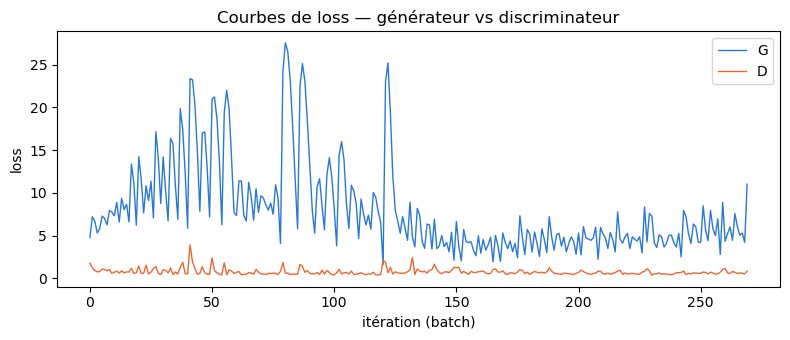

In [9]:
plt.figure(figsize=(8, 3.5))
plt.plot(G_losses, label="G", color="#2a78d6", linewidth=1)
plt.plot(D_losses, label="D", color="#eb6834", linewidth=1)
plt.xlabel("itération (batch)")
plt.ylabel("loss")
plt.title("Courbes de loss — générateur vs discriminateur")
plt.legend()
plt.tight_layout()
plt.show()


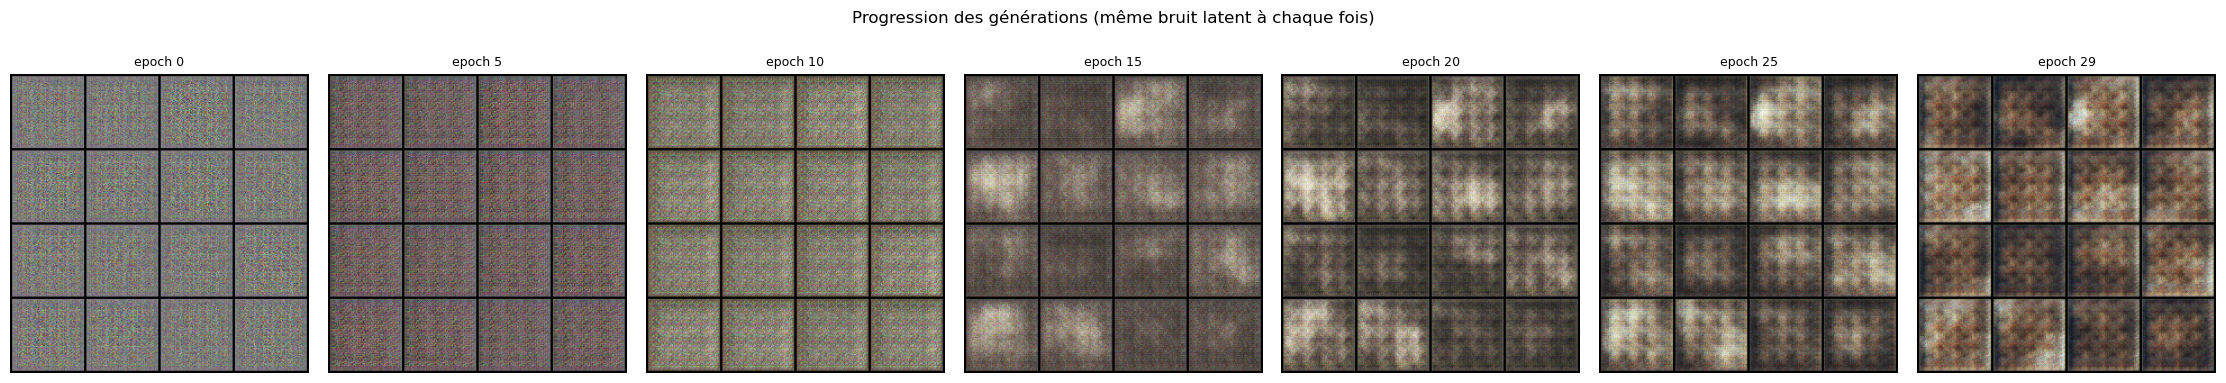

In [10]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(3.2 * len(snapshots), 3.6))
axes = [axes] if len(snapshots) == 1 else axes
for ax, (ep, grid) in zip(axes, snapshots):
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_title(f"epoch {ep}", fontsize=9)
    ax.axis("off")
fig.suptitle("Progression des générations (même bruit latent à chaque fois)", y=1.05)
plt.tight_layout()
plt.show()


## 6. Comparaison finale réel vs généré

**Résultat.** Textures et couleurs plausibles à l'epoch 29, pas encore de
formes reconnaissables — attendu à cette échelle (154 images, 30 epochs).


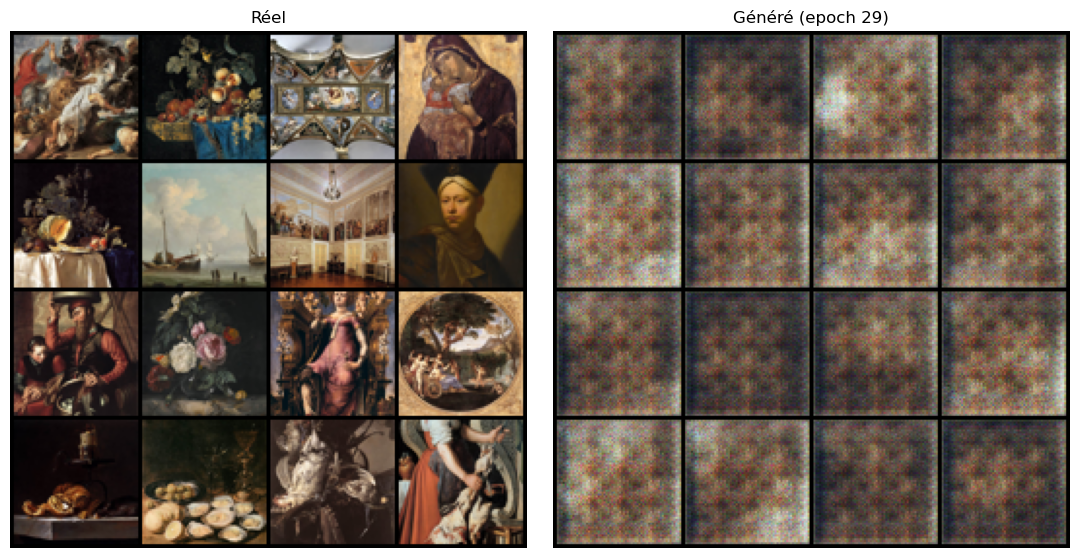

In [11]:
with torch.no_grad():
    final_fake = netG(fixed_noise).cpu()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(make_grid(real_batch, nrow=4, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
axes[0].set_title("Réel")
axes[0].axis("off")
axes[1].imshow(make_grid(final_fake, nrow=4, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
axes[1].set_title(f"Généré (epoch {EPOCHS - 1})")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 7. Confirmation de sauvegarde

**Résultat.** `checkpoints/generator.pt` et `checkpoints/discriminator.pt`
sauvegardés avec succès.


In [ ]:
print("Checkpoints (générateur, discriminateur, epoch, historique des loss) dans", CKPT_DIR.resolve())
for f in sorted(CKPT_DIR.iterdir()):
    print(" -", f.name)


## Conclusion

Le notebook est maintenant prévu pour un vrai entraînement, pas seulement une
démonstration :
- il s'entraîne sur le **sous-échantillon stratifié** (`data/subset_sample.csv`)
  plutôt que sur un mélange arbitraire de fichiers de test présents dans
  `images/`,
- il **reprend automatiquement** d'un run interrompu (checkpoints tous les
  `CKPT_EVERY` epochs),
- il vise **300 epochs** par défaut.

**Prochaines étapes concrètes :**
- laisser `scraping_images.ipynb` (ou sa variante Colab) terminer le
  téléchargement des ~4 000 images du sous-échantillon — plus il y en a de
  disponibles, mieux c'est, pas besoin d'attendre que ce soit fini à 100 % pour
  relancer ce notebook,
- si le calcul local devient le facteur limitant, migrer l'exécution (pas le
  scraping) sur le GPU gratuit de Colab via la section 0,
- si les courbes de loss montrent un mode collapse (D qui écrase G,
  génération qui se fige sur une seule image), basculer vers **hinge loss**
  ou **LSGAN** — un changement localisé à la cellule 3/4, le reste ne change
  pas.
